In [1]:
###INDIRECT IMPACTS FREDDY

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [2]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupt_imph2.pkl', 'rb') as file:
    disrupt_imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupt_pp1.pkl', 'rb') as file:
    disrupt_pp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph1.pkl', 'rb') as file:
    imph1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/imph1_cat.pkl', 'rb') as file:
    imph1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp3.pkl', 'rb') as file:
#    impp3 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp5.pkl', 'rb') as file:
    impp5 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp6.pkl', 'rb') as file:
    impp6 = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp7.pkl', 'rb') as file:
#    impp7 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [3]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [4]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [5]:
import geopandas as gpd
from shapely.geometry import Point

def get_disrupted_exposures_by_latlon(imph2_dict, exp_gdf, threshold=0.20, min_members=5, mode="above", lower=None, upper=None):
    """
    Identify disrupted exposures (hospitals) and assign levels using exact latitude/longitude match.

    Parameters:
    - imph2_dict: dict[str, Impact] with .imp_mat and .coord_exp
    - exp_gdf: GeoDataFrame with ['latitude', 'longitude', 'levels']
    - threshold: threshold value for disruption
    - min_members: minimum number of ensemble members
    - mode: 'above' or 'range'
    - lower, upper: bounds for 'range' mode

    Returns:
    - dict[str, GeoDataFrame] with disrupted points and hospital levels
    """
    disrupted_exposures_dict = {}

    # Ensure proper CRS
    exp_gdf = exp_gdf.set_crs("EPSG:4326")

    for key, impact_obj in imph2_dict.items():
        imp_matrix = impact_obj.imp_mat.toarray().T

        if mode == "above":
            mask = imp_matrix >= threshold
        elif mode == "range":
            if lower is None or upper is None:
                raise ValueError("Specify both lower and upper for 'range' mode.")
            mask = (imp_matrix > lower) & (imp_matrix < upper)
        else:
            raise ValueError("Invalid mode. Use 'above' or 'range'.")

        count_mask = mask.sum(axis=1)
        disrupted_mask = count_mask >= min_members
        coords = impact_obj.coord_exp[disrupted_mask]

        disrupted_gdf = gpd.GeoDataFrame({
            "latitude": coords[:, 0],
            "longitude": coords[:, 1],
            "n_ensemble_members": count_mask[disrupted_mask],
            "geometry": [Point(lon, lat) for lat, lon in coords]
        }, crs="EPSG:4326")

        # Merge by exact lat/lon
        merged = disrupted_gdf.merge(
            exp_gdf[['latitude', 'longitude', 'levels']],
            on=['latitude', 'longitude'],
            how='left'
        )

        disrupted_exposures_dict[key] = merged

    return disrupted_exposures_dict

In [6]:
# Import your function
disrupted_hospitals = get_disrupted_exposures_by_latlon(
    imph2_dict=imph2,
    exp_gdf=exp_dict['exp_h2_MOZ'].gdf,
    threshold=0.2,
    min_members=10,
    mode='above'
)
disrupted_hospitals_copy = disrupted_hospitals.copy()

In [7]:
disrupted_hospitals_copy ['imph2_MOZ_new_FREDDY_20230310120000']

,latitude,longitude,n_ensemble_members,geometry,levels
0,-17.875456,36.881978,51,POINT (36.88198 -17.87546),2
1,-19.746900,34.860563,16,POINT (34.86056 -19.7469),2
2,-19.363976,34.574852,22,POINT (34.57485 -19.36398),1
3,-19.618176,34.741218,21,POINT (34.74122 -19.61818),1
4,-19.687157,34.760013,17,POINT (34.76001 -19.68716),1
...,...,...,...,...,...
212,-16.468077,35.815653,38,POINT (35.81565 -16.46808),4
213,-17.819074,36.946705,51,POINT (36.94671 -17.81907),4
214,-16.840426,36.987009,46,POINT (36.98701 -16.84043),4
215,-15.768335,36.021872,11,POINT (36.02187 -15.76834),1


In [8]:
### FIRST OPTION ABOVE 0,20 IN EACH ENSEMBLE MEMBER AND IN 5 ENSEMBLE MEMBERS AT LEATS 
###PEOPLE AFFECTED AS WELLimport numpy as np
import geopandas as gpd
from shapely.geometry import Point

def get_disrupted_exposures_and_ensemble(imph2_dict, threshold=0.20, min_members=5, mode="above", lower=None, upper=None):
    """
    Extract disrupted exposure points from imph2 dictionary based on impact threshold.

    Parameters:
    - imph2_dict (dict): Dictionary with impact matrices.
    - threshold (float): Threshold for 'above' mode (default 0.20).
    - min_members (int): Minimum ensemble members needed.
    - mode (str): 'above' or 'range'.
    - lower (float): Lower bound for 'range' mode (exclusive).
    - upper (float): Upper bound for 'range' mode (exclusive).

    Returns:
    - disrupted_exposures_dict (dict): Dictionary of GeoDataFrames with disrupted exposures and member count.
    """
    disrupted_exposures_dict = {}

    for key, impact_obj in imph2_dict.items():
        imp_matrix = impact_obj.imp_mat.toarray()     # (51, N)
        imp_matrix_T = imp_matrix.T                   # (N, 51)

        if mode == "above":
            mask = imp_matrix_T >= threshold
        elif mode == "range":
            if lower is None or upper is None:
                raise ValueError("For 'range' mode, both 'lower' and 'upper' must be provided.")
            mask = (imp_matrix_T > lower) & (imp_matrix_T < upper)
        else:
            raise ValueError("Invalid mode. Choose 'above' or 'range'.")

        count_mask = mask.sum(axis=1)                 # number of members ≥ threshold per exposure
        disrupted_mask = count_mask >= min_members    # boolean: exposures considered disrupted

        coords = impact_obj.coord_exp[disrupted_mask]
        latitudes = coords[:, 0]
        longitudes = coords[:, 1]
        member_counts = count_mask[disrupted_mask]    # ensemble counts for disrupted only

        disrupted_gdf = gpd.GeoDataFrame({
            "latitude": latitudes,
            "longitude": longitudes,
            "n_ensemble_members": member_counts,
            "geometry": [Point(lon, lat) for lat, lon in coords]
        }, crs="EPSG:4326")

        disrupted_exposures_dict[key] = disrupted_gdf

    return disrupted_exposures_dict

In [9]:
imph1 ['imph1_MOZ_FREDDY_20230306120000'].imp_mat[40].data

array([0.00039695, 0.00096804])

In [10]:
disrupted_hospitals_imph1 = get_disrupted_exposures_and_ensemble(imph1, threshold=0.20, min_members=5, mode="above")
disrupted_hospitals_imph1_copy = disrupted_hospitals_imph1.copy()

In [11]:
disrupted_hospitals_imph1cat = get_disrupted_exposures_and_ensemble(imph1_cat, threshold=0.20, min_members=5, mode="above")
disrupted_hospitals_imph1cat_copy = disrupted_hospitals_imph1cat.copy()

In [13]:
disrupted_hospitals_imph1cat_copy ['imph1_MOZ_FREDDY_20230306120000']

,latitude,longitude,n_ensemble_members,geometry
0,-17.875456,36.881978,13,POINT (36.88198 -17.87546)
1,-18.076296,36.927779,14,POINT (36.92778 -18.0763)
2,-17.329902,37.199672,13,POINT (37.19967 -17.3299)
3,-18.268417,36.650071,9,POINT (36.65007 -18.26842)
4,-16.967314,38.049346,9,POINT (38.04935 -16.96731)
...,...,...,...,...
62,-17.861562,36.895210,13,POINT (36.89521 -17.86156)
63,-16.639303,39.496035,5,POINT (39.49603 -16.6393)
64,-17.309223,37.508866,15,POINT (37.50887 -17.30922)
65,-17.894702,36.766469,12,POINT (36.76647 -17.8947)


In [14]:
disrupted_schools = get_disrupted_exposures_and_ensemble(ed2, threshold=0.20, min_members=5, mode="above")
disrupted_schools_copy = disrupted_schools.copy()

In [15]:
disrupted_schools ['ed2_MOZ_new_FREDDY_20230306120000']

,latitude,longitude,n_ensemble_members,geometry
0,-19.642206,34.755461,6,POINT (34.75546 -19.64221)
1,-15.713179,39.339554,6,POINT (39.33955 -15.71318)
2,-15.719660,39.342461,6,POINT (39.34246 -15.71966)
3,-17.102473,38.218907,27,POINT (38.21891 -17.10247)
4,-16.814676,36.994455,23,POINT (36.99445 -16.81468)
...,...,...,...,...
105,-16.181556,33.628341,5,POINT (33.62834 -16.18156)
106,-15.743185,39.751738,6,POINT (39.75174 -15.74318)
107,-16.207444,39.887358,12,POINT (39.88736 -16.20744)
108,-19.793435,34.871428,6,POINT (34.87143 -19.79343)


In [16]:
impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")

In [17]:
impp2_disrupted = get_disrupted_exposures_and_ensemble(impp2, threshold=0.20, min_members=5, mode="above")

In [18]:
### I want to add people and NAME_1 
import geopandas as gpd
import numpy as np
from shapely.geometry import Point
from scipy.spatial import cKDTree

def add_population_and_region_to_disrupted(impp1_disrupted_dict, gdf_worldpop, gadm_MOZ_gdf):
    """
    Add population and region (NAME_1) to each disrupted point GeoDataFrame in a dictionary.

    Parameters:
    - impp1_disrupted_dict (dict): Dictionary of GeoDataFrames (disrupted points).
    - gdf_worldpop (GeoDataFrame or Exposures): Must have 'geometry' and 'people'.
    - gadm_MOZ_gdf (GeoDataFrame): Administrative boundaries with 'NAME_1' and 'geometry'.

    Returns:
    - updated_dict (dict): Dictionary with updated GeoDataFrames containing 'people' and 'NAME_1'.
    """
    # If gdf_worldpop is a CLIMADA Exposures object, extract the .gdf
    if hasattr(gdf_worldpop, 'gdf'):
        gdf_worldpop = gdf_worldpop.gdf

    # Reproject to EPSG:4326
    gdf_worldpop = gdf_worldpop.to_crs(epsg=4326)
    gadm_MOZ_gdf = gadm_MOZ_gdf.to_crs(epsg=4326)

    # Precompute centroids and KDTree once for speed
    centroids = gadm_MOZ_gdf.geometry.centroid
    centroid_coords = np.array([[pt.x, pt.y] for pt in centroids])
    kdtree = cKDTree(centroid_coords)

    updated_dict = {}

    for key, gdf in impp1_disrupted_dict.items():
        gdf = gdf.to_crs(epsg=4326)

        # Join population by exact geometry match
        gdf = gdf.merge(
            gdf_worldpop[['geometry', 'people']],
            on='geometry',
            how='left'
        )
        gdf['people'] = gdf['people'].fillna(0).astype(int)

        # Spatial join to get NAME_1 (region)
        gdf = gpd.sjoin(
            gdf, gadm_MOZ_gdf[['geometry', 'NAME_1']],
            how='left',
            predicate='intersects'
        ).drop(columns='index_right')

        # Handle unmatched with fast KDTree
        unmatched = gdf[gdf['NAME_1'].isna()]
        if not unmatched.empty:
            print(f" {len(unmatched)} unmatched points in {key} — assigning nearest NAME_1 using KDTree...")

            unmatched_coords = np.array([[pt.x, pt.y] for pt in unmatched.geometry])
            _, nearest_idxs = kdtree.query(unmatched_coords, k=1)

            # Assign nearest NAME_1 from GADM
            gdf.loc[unmatched.index, 'NAME_1'] = gadm_MOZ_gdf.iloc[nearest_idxs]['NAME_1'].values

        updated_dict[key] = gdf

    return updated_dict

In [19]:
impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf,gadm_MOZ_gdf)
impp1_disrupted_copy = impp1_disrupted.copy()

/scratch/tmp.34233965.gespejo/ipykernel_797396/2390560494.py:28: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gadm_MOZ_gdf.geometry.centroid


 222412 unmatched points in impp1_MOZ_FREDDY_20230306120000 — assigning nearest NAME_1 using KDTree...
 178720 unmatched points in impp1_MOZ_FREDDY_20230307120000 — assigning nearest NAME_1 using KDTree...
 58099 unmatched points in impp1_MOZ_FREDDY_20230308120000 — assigning nearest NAME_1 using KDTree...
 56150 unmatched points in impp1_MOZ_FREDDY_20230309120000 — assigning nearest NAME_1 using KDTree...
 57574 unmatched points in impp1_MOZ_FREDDY_20230310120000 — assigning nearest NAME_1 using KDTree...
 10333 unmatched points in impp1_MOZ_FREDDY_20230311120000 — assigning nearest NAME_1 using KDTree...


In [21]:
impp1_disrupted_copy ['impp1_MOZ_FREDDY_20230306120000']

,latitude,longitude,n_ensemble_members,geometry,people,NAME_1
0,-16.62125,37.261250,5,POINT (37.26125 -16.62125),48,Zambezia
1,-16.62125,37.269583,5,POINT (37.26958 -16.62125),44,Zambezia
2,-16.62125,37.277917,5,POINT (37.27792 -16.62125),54,Zambezia
3,-16.62125,37.286250,5,POINT (37.28625 -16.62125),52,Zambezia
4,-16.62125,37.294583,5,POINT (37.29458 -16.62125),49,Zambezia
...,...,...,...,...,...,...
260143,-22.49625,40.586250,5,POINT (40.58625 -22.49625),0,Inhambane
260144,-22.49625,40.594583,5,POINT (40.59458 -22.49625),0,Inhambane
260145,-22.49625,40.602917,5,POINT (40.60292 -22.49625),0,Inhambane
260146,-22.49625,40.611250,5,POINT (40.61125 -22.49625),0,Inhambane


In [22]:
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'impp1_disrupted.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted, file)

In [23]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'disrupted_hospitals.pkl', 'wb') as file:
    pickle.dump(disrupted_hospitals, file) 

In [24]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'disrupted_schools.pkl', 'wb') as file:
    pickle.dump(disrupted_schools, file)

In [160]:
###FIND PEOPLE AFFECTED WHEN A HOSPITAL IS DISRUPTED 

In [25]:
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree

def cal_nearestpop_to_infrastructure(disrupted_hospitals, impp1_disrupted_dict):
    """
    Assign nearest affected population and NAME_1 region from disrupted population points
    to each disrupted infrastructure point (e.g., hospitals).

    Parameters:
    - disrupted_hospitals (dict): GeoDataFrames of disrupted hospitals.
    - impp1_disrupted_dict (dict): GeoDataFrames of affected population with 'people' and 'NAME_1'.

    Returns:
    - updated_hospitals_dict (dict): Dictionary with 'pp_affected' and 'NAME_1' assigned from nearest population.
    """

    updated_hospitals_dict = {}

    keys_hosp = sorted(disrupted_hospitals.keys())
    keys_pop = sorted(impp1_disrupted_dict.keys())

    print(f"\n🔍 Starting nearest population match for {len(keys_hosp)} lead times...")

    for hosp_key, pop_key in zip(keys_hosp, keys_pop):
        gdf_hosp = disrupted_hospitals[hosp_key]
        gdf_pop = impp1_disrupted_dict[pop_key]

        print(f"\n➡️  Processing: {hosp_key} | {pop_key}")

        if gdf_hosp.empty:
            print(f" ⏩ SKIPPED: No hospitals in {hosp_key}")
            continue
        if gdf_pop.empty:
            print(f" ⏩ SKIPPED: No population data in {pop_key}")
            continue

        try:
            # Coordinates
            hosp_coords = np.array([[pt.x, pt.y] for pt in gdf_hosp.geometry])
            pop_coords = np.array([[pt.x, pt.y] for pt in gdf_pop.geometry])

            # KDTree search
            tree = cKDTree(pop_coords)
            _, idx = tree.query(hosp_coords, k=1)

            # Add values from nearest population point
            gdf_hosp['nearest_pop_index'] = idx
            gdf_hosp['pp_affected'] = gdf_hosp['nearest_pop_index'].apply(
                lambda i: gdf_pop.iloc[i]['people']
            ).fillna(0).round(0).astype(int)

            gdf_hosp['NAME_1'] = gdf_hosp['nearest_pop_index'].apply(
                lambda i: gdf_pop.iloc[i]['NAME_1']
            )

            updated_hospitals_dict[hosp_key] = gdf_hosp
            print(f" ✅ SUCCESS: Population + NAME_1 assigned to {hosp_key}")

        except Exception as e:
            print(f" ❌ ERROR in {hosp_key}: {e}")

    print("\n✅ All processing complete.")
    return updated_hospitals_dict

In [26]:
imph1_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_imph1_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 6 lead times...

➡️  Processing: imph1_MOZ_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230306120000

➡️  Processing: imph1_MOZ_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230307120000

➡️  Processing: imph1_MOZ_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230308120000

➡️  Processing: imph1_MOZ_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230309120000

➡️  Processing: imph1_MOZ_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230310120000

➡️  Processing: imph1_MOZ_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230311120000

✅ All processing complete.


In [27]:
imph1_impp1cat = cal_nearestpop_to_infrastructure(disrupted_hospitals_imph1cat_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 6 lead times...

➡️  Processing: imph1_MOZ_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230306120000

➡️  Processing: imph1_MOZ_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230307120000

➡️  Processing: imph1_MOZ_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_FREDDY_20230308120000

➡️  Processing: imph1_MOZ_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230309120000

➡️  Processing: imph1_MOZ_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230310120000

➡️  Processing: imph1_MOZ_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230311120000

✅ Al

In [28]:
imph1_impp1cat ['imph1_MOZ_FREDDY_20230306120000']

,latitude,longitude,n_ensemble_members,geometry,nearest_pop_index,pp_affected,NAME_1
0,-17.875456,36.881978,13,POINT (36.88198 -17.87546),75073,2779,Zambezia
1,-18.076296,36.927779,14,POINT (36.92778 -18.0763),88600,87,Zambezia
2,-17.329902,37.199672,13,POINT (37.19967 -17.3299),37888,107,Zambezia
3,-18.268417,36.650071,9,POINT (36.65007 -18.26842),101424,29,Zambezia
4,-16.967314,38.049346,9,POINT (38.04935 -16.96731),14889,54,Zambezia
...,...,...,...,...,...,...,...
62,-17.861562,36.895210,13,POINT (36.89521 -17.86156),73927,7341,Zambezia
63,-16.639303,39.496035,5,POINT (39.49603 -16.6393),674,594,Nampula
64,-17.309223,37.508866,15,POINT (37.50887 -17.30922),36807,1795,Zambezia
65,-17.894702,36.766469,12,POINT (36.76647 -17.8947),76208,43,Zambezia


In [29]:
imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 6 lead times...

➡️  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230306120000

➡️  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230307120000

➡️  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230308120000

➡️  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230309120000

➡️  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

➡️  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
 ✅ SUCCESS: Populatio

In [30]:
imph2_impp1 ['imph2_MOZ_new_FREDDY_20230310120000']

,latitude,longitude,n_ensemble_members,geometry,levels,nearest_pop_index,pp_affected,NAME_1
0,-17.875456,36.881978,51,POINT (36.88198 -17.87546),2,23105,2779,Zambezia
1,-19.746900,34.860563,16,POINT (34.86056 -19.7469),2,83483,0,Sofala
2,-19.363976,34.574852,22,POINT (34.57485 -19.36398),1,56440,1,Sofala
3,-19.618176,34.741218,21,POINT (34.74122 -19.61818),1,83483,0,Sofala
4,-19.687157,34.760013,17,POINT (34.76001 -19.68716),1,83483,0,Sofala
...,...,...,...,...,...,...,...,...
212,-16.468077,35.815653,38,POINT (35.81565 -16.46808),4,4568,5,Zambezia
213,-17.819074,36.946705,51,POINT (36.94671 -17.81907),4,20488,1276,Zambezia
214,-16.840426,36.987009,46,POINT (36.98701 -16.84043),4,0,20,Zambezia
215,-15.768335,36.021872,11,POINT (36.02187 -15.76834),1,1008,31,Zambezia


In [31]:
###FIND PEOPLE AFFECTED WHEN A HOSPITAL IS DISRUPTED 

In [32]:
ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 6 lead times...

➡️  Processing: ed2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_FREDDY_20230306120000

➡️  Processing: ed2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_FREDDY_20230307120000

➡️  Processing: ed2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_FREDDY_20230308120000

➡️  Processing: ed2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_FREDDY_20230309120000

➡️  Processing: ed2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_FREDDY_20230310120000

➡️  Processing: ed2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
 ✅ SUCCESS: Population + NAME_1 assigned to

In [33]:
ed2_impp1 ['ed2_MOZ_new_FREDDY_20230311120000'] 

,latitude,longitude,n_ensemble_members,geometry,nearest_pop_index,pp_affected,NAME_1
0,-19.642206,34.755461,5,POINT (34.75546 -19.64221),17118,19,Zambezia
1,-17.102473,38.218907,36,POINT (38.21891 -17.10247),4233,0,Zambezia
2,-16.814676,36.994455,47,POINT (36.99445 -16.81468),54,125,Zambezia
3,-16.099327,35.765580,17,POINT (35.76558 -16.09933),0,17,Zambezia
4,-16.170630,35.806724,23,POINT (35.80672 -16.17063),0,17,Zambezia
...,...,...,...,...,...,...,...
73,-17.018025,38.718091,13,POINT (38.71809 -17.01803),4233,0,Zambezia
74,-17.531390,36.853644,51,POINT (36.85364 -17.53139),725,87,Zambezia
75,-15.962585,34.000091,6,POINT (34.00009 -15.96258),2494,14,Zambezia
76,-15.883576,34.027706,6,POINT (34.02771 -15.88358),2494,14,Zambezia


In [34]:
## FOR ROADS

In [35]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)

In [36]:
# Example usage
###roads
def join_road_exp_51ens(ens_51, exposure_gdf):
    results = {}
    for key, df in ens_51.items():
        df = df.reset_index(drop=True)
        exposure_gdf = exposure_gdf.reset_index(drop=True)

        if len(df) == len(exposure_gdf):
            df['osm_id'] = exposure_gdf['osm_id']
        else:
            raise ValueError(f"Mismatch in DataFrame lengths for key: {key}")

        grouped = df.groupby('osm_id').mean()
        first_geometry = exposure_gdf.drop_duplicates(subset=['osm_id'])[['osm_id', 'geometry_orig']]
        merged_grouped = grouped.merge(first_geometry, on='osm_id', how='left')

        column_range = list(range(51))
        merged_grouped['mean_impact'] = merged_grouped[column_range].mean(axis=1)

        # Keep all ensemble columns, 'mean_impact', and 'geometry_orig'
        ensemble_cols = [col for col in merged_grouped.columns if isinstance(col, int) or col == 'mean_impact']
        final_cols = ['osm_id'] + ensemble_cols + ['geometry_orig']
        final_result = merged_grouped[final_cols]

        geo_df = gpd.GeoDataFrame(final_result, geometry='geometry_orig')
        geo_df.set_crs(epsg=4326, inplace=True)

        results[key] = geo_df

    return results

In [37]:
### scale 
def mimpact_cols_scale(data_dict, divisor):
    """
    Scales columns 0 to 50 and 'mean_impact' in all DataFrames within a dictionary.

    Parameters:
    data_dict (dict): Dictionary containing the DataFrames.
    divisor (int or float): Value by which to divide the column values.

    Returns:
    None; the operation modifies the DataFrames in place.
    """
    for key, df in data_dict.items():
        # Select columns that are integers from 0 to 50 or 'mean_impact'
        cols_to_scale = [col for col in df.columns if 
                         (isinstance(col, int) and 0 <= col <= 50) or col == 'mean_impact']
        
        # Only scale if those columns are present
        if cols_to_scale:
            df[cols_to_scale] = df[cols_to_scale] / divisor
        else:
            print(f"No matching columns found in DataFrame for key '{key}'.")

In [38]:
rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_dict['exp_rd2_MOZ'].gdf)

In [39]:
mimpact_cols_scale(rd2_mimpact, 500.0)

In [40]:
def get_disrupted_road(exposure_dict, threshold=0.20, min_members=5, mode="above", lower=None, upper=None):
    """
    Filters exposures disrupted in at least `min_members` ensemble members using one of two modes.

    Returns:
    - dict of filtered GeoDataFrames by lead time key, keeping the 'geometry_orig' column if present.
    """
    disrupted_dict = {}

    for lead_time_key, gdf in exposure_dict.items():
        ens_cols = [col for col in gdf.columns if isinstance(col, int) and 0 <= col <= 50]
        impact_array = gdf[ens_cols].values

        if mode == "above":
            count_disrupted = (impact_array >= threshold).sum(axis=1)
        elif mode == "range":
            if lower is None or upper is None:
                raise ValueError("Both lower and upper bounds must be set for 'range' mode.")
            count_disrupted = ((impact_array >= lower) & (impact_array <= upper)).sum(axis=1)
        else:
            raise ValueError("Invalid mode. Use 'above' or 'range'.")

        mask = count_disrupted >= min_members

        # Start with selected ensemble columns
        filtered = gdf.loc[mask, ens_cols].copy()

        # Preserve osm_id if available
        if 'osm_id' in gdf.columns:
            filtered.insert(0, 'osm_id', gdf.loc[mask, 'osm_id'].values)

        # Preserve geometry_orig if present
        if 'geometry_orig' in gdf.columns:
            filtered['geometry_orig'] = gdf.loc[mask, 'geometry_orig'].values

        # ✅ Fix applied here
        filtered["n_ensemble_members"] = count_disrupted[mask]

        # Convert to GeoDataFrame with geometry if available
        if 'geometry' in gdf.columns:
            filtered = gpd.GeoDataFrame(filtered, geometry=gdf.loc[mask, 'geometry'], crs=gdf.crs)

        disrupted_dict[lead_time_key] = filtered

    return disrupted_dict

In [41]:
rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")

In [42]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'rd2_disrupted.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted, file)

In [43]:
def add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads):
    """
    Merge road geometry into each disrupted roads DataFrame by osm_id.
    
    Parameters:
    - rd2_disrupted: dict of DataFrames with disrupted roads per lead time
    - gdf_roads: GeoDataFrame with 'osm_id' and 'geometry'
    
    Returns:
    - dict with same keys as rd2_disrupted, each value a DataFrame with geometry
    """
    result = {}
    for key, df in rd2_disrupted.items():
        merged = df.merge(
            gdf_roads[['osm_id', 'geometry']],
            on='osm_id',
            how='left'
        )
        result[key] = merged
    return result

In [44]:
rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
rd2_disrupted_copy = rd2_disrupted.copy()

In [45]:
###disruption 
from shapely.geometry import LineString
from sklearn.neighbors import BallTree
import numpy as np

def calc_pp_byroaddisrup_5ens(disrupt_rd2_dict, disrupt_pp1_dict, radius_km=2):
    """
    Calculate the total number of people affected within a 2 km radius of the midpoint of each LineString
    in each GeoDataFrame within disrupt_rd2_dict, using population data in disrupt_pp1_dict.
    Ensures no double-counting of affected people.
    Skips any keys where either GeoDataFrame is empty.
    """
    result_dict = {}

    # Extract date keys from disrupt_pp1_dict and create a mapping
    pp1_date_mapping = {key.split('_')[-1]: key for key in disrupt_pp1_dict.keys()}

    # Initialize a set to keep track of counted population indices to avoid double-counting
    counted_indices = set()

    # Iterate over each entry in disrupt_rd2_dict
    for rd2_key, disrupt_rd2 in disrupt_rd2_dict.items():
        # Attempt to match the date portion in rd2_key with a key in disrupt_pp1_dict
        pp1_key = pp1_date_mapping.get(rd2_key)

        if pp1_key is None:
            print(f"Warning: No population data found for key {rd2_key}. Skipping.")
            continue

        # Retrieve the corresponding GeoDataFrame for disrupt_pp1
        disrupt_pp1 = disrupt_pp1_dict[pp1_key]

        # Skip if either dataframe is empty
        if disrupt_rd2.empty:
            print(f"Skipping {rd2_key}: Road data is empty.")
            continue
        if disrupt_pp1.empty:
            print(f"Skipping {pp1_key}: Population data is empty.")
            continue

        # Set 'geometry_orig' as the geometry column if it exists in disrupt_rd2
        if 'geometry' in disrupt_rd2.columns:
            disrupt_rd2 = disrupt_rd2.set_geometry('geometry')
        else:
            raise KeyError(f"ERROR: 'geometry_orig' missing in {rd2_key} GeoDataFrame.")

        # Calculate midpoints for each LineString in disrupt_rd2
        disrupt_rd2['midpoint'] = disrupt_rd2.geometry.apply(
            lambda line: line.interpolate(0.5, normalized=True) if isinstance(line, LineString) else None
        )

        # Filter out any None values that may arise if geometry isn't a LineString
        disrupt_rd2 = disrupt_rd2.dropna(subset=['midpoint'])
        if disrupt_rd2.empty:
            print(f"Skipping {rd2_key}: No valid midpoints after filtering.")
            continue

        # Extract coordinates for midpoints and population points
        midpoints_coords = np.array([(point.x, point.y) for point in disrupt_rd2['midpoint']])
        pop_coords = np.array([(point.x, point.y) for point in disrupt_pp1.geometry])

        # Skip if coordinates are empty
        if pop_coords.size == 0:
            print(f"Skipping {pp1_key}: Population coordinates are empty.")
            continue
        if midpoints_coords.size == 0:
            print(f"Skipping {rd2_key}: Midpoints coordinates are empty.")
            continue

        # Initialize BallTree for fast spatial queries
        try:
            tree = BallTree(np.radians(pop_coords), metric='haversine')
        except Exception as e:
            print(f"ERROR building BallTree for {rd2_key}: {e}")
            continue

        midpoints_radians = np.radians(midpoints_coords)
        radius_radians = radius_km / 6371.0

        # Calculate affected people for each midpoint
        affected_population = []
        for midpoint in midpoints_radians:
            indices = tree.query_radius([midpoint], r=radius_radians)[0]
            unique_indices = [idx for idx in indices if idx not in counted_indices]
            total_affected = disrupt_pp1.iloc[unique_indices]['people'].sum()
            affected_population.append(total_affected)
            counted_indices.update(unique_indices)

        # Add the affected population to disrupt_rd2
        disrupt_rd2['pp_affected'] = affected_population
        disrupt_rd2 = disrupt_rd2.drop(columns=['midpoint'])
        result_dict[rd2_key] = disrupt_rd2

        print(f" Finished processing {rd2_key}. Affected population calculated.\n")

    return result_dict

In [46]:
rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)

 Finished processing 20230306120000. Affected population calculated.

 Finished processing 20230307120000. Affected population calculated.

 Finished processing 20230308120000. Affected population calculated.

 Finished processing 20230309120000. Affected population calculated.

 Finished processing 20230310120000. Affected population calculated.

 Finished processing 20230311120000. Affected population calculated.



In [47]:
def assign_province_to_roads(rd2_disrupted_impp1_dict, gadm_moz):
    updated_dict = {}
    gadm_moz = gadm_moz.to_crs(4326)

    for key, gdf in rd2_disrupted_impp1_dict.items():
        if gdf.empty:
            updated_dict[key] = gdf
            continue

        gdf = gdf.copy()
        gdf = gdf.set_geometry('geometry')

        # Fix missing CRS
        if gdf.crs is None:
            gdf.set_crs(4326, inplace=True)
        else:
            gdf = gdf.to_crs(4326)

        gdf_with_province = gpd.sjoin(
            gdf, gadm_moz[['NAME_1', 'geometry']], how='left', predicate='intersects'
        ).drop(columns=['index_right'])

        updated_dict[key] = gdf_with_province

    return updated_dict

In [48]:
rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)

In [49]:
rd2_disrupted_impp1

{'20230306120000':            osm_id         0    1    2         3         4         5    6    7  \
 0      1000099478  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 1      1000099479  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 2      1000430904  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 3      1001375959  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 4      1001694070  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 ...           ...       ...  ...  ...       ...       ...       ...  ...  ...   
 80393   999858614  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80394   999859262  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80395   999860028  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80396   999865566  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80397   999866041  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0  

In [51]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1.pkl', 'wb') as file:
    pickle.dump(imph2_impp1, file)
with open(save_dir_pickle + 'ed2_impp1.pkl', 'wb') as file:
    pickle.dump(ed2_impp1, file)
with open(save_dir_pickle + 'impp1_disrupted.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1, file)

In [50]:
## PLOTTING 

In [52]:
rename_dict = {
    'imph2_MOZ_new_FREDDY_20230306120000': '5 days',
    'imph2_MOZ_new_FREDDY_20230307120000': '4 days',
    'imph2_MOZ_new_FREDDY_20230308120000': '3 days',
    'imph2_MOZ_new_FREDDY_20230309120000': '2 days',
    'imph2_MOZ_new_FREDDY_20230310120000': '1 day',
    'imph2_MOZ_new_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
imph2_impp1 = {rename_dict.get(k, k): v for k, v in imph2_impp1.items() if k in rename_dict}

In [53]:
rename_dict_impp1_disrupted = {
    'impp1_MOZ_FREDDY_20230306120000': '5 days',
    'impp1_MOZ_FREDDY_20230307120000': '4 days',
    'impp1_MOZ_FREDDY_20230308120000': '3 days',
    'impp1_MOZ_FREDDY_20230309120000': '2 days',
    'impp1_MOZ_FREDDY_20230310120000': '1 day',
    'impp1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
impp1_disrupted  = {rename_dict_impp1_disrupted.get(k, k): v for k, v in impp1_disrupted .items() if k in rename_dict_impp1_disrupted}

In [54]:
###For schools 

In [55]:
rename_dict_ed2 = {
    'ed2_MOZ_new_FREDDY_20230306120000': '5 days',
    'ed2_MOZ_new_FREDDY_20230307120000': '4 days',
    'ed2_MOZ_new_FREDDY_20230308120000': '3 days',
    'ed2_MOZ_new_FREDDY_20230309120000': '2 days',
    'ed2_MOZ_new_FREDDY_20230310120000': '1 day',
    'ed2_MOZ_new_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
ed2_impp1 = {rename_dict_ed2.get(k, k): v for k, v in ed2_impp1.items() if k in rename_dict_ed2}

In [56]:
###For roads

In [57]:
rename_dict_rd2 = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}
# Rename keys using rename_dict
rd2_disrupted_impp1 = {rename_dict_rd2.get(k, k): v for k, v in rd2_disrupted_impp1.items() if k in rename_dict_rd2}

In [195]:
## PLOTTING 

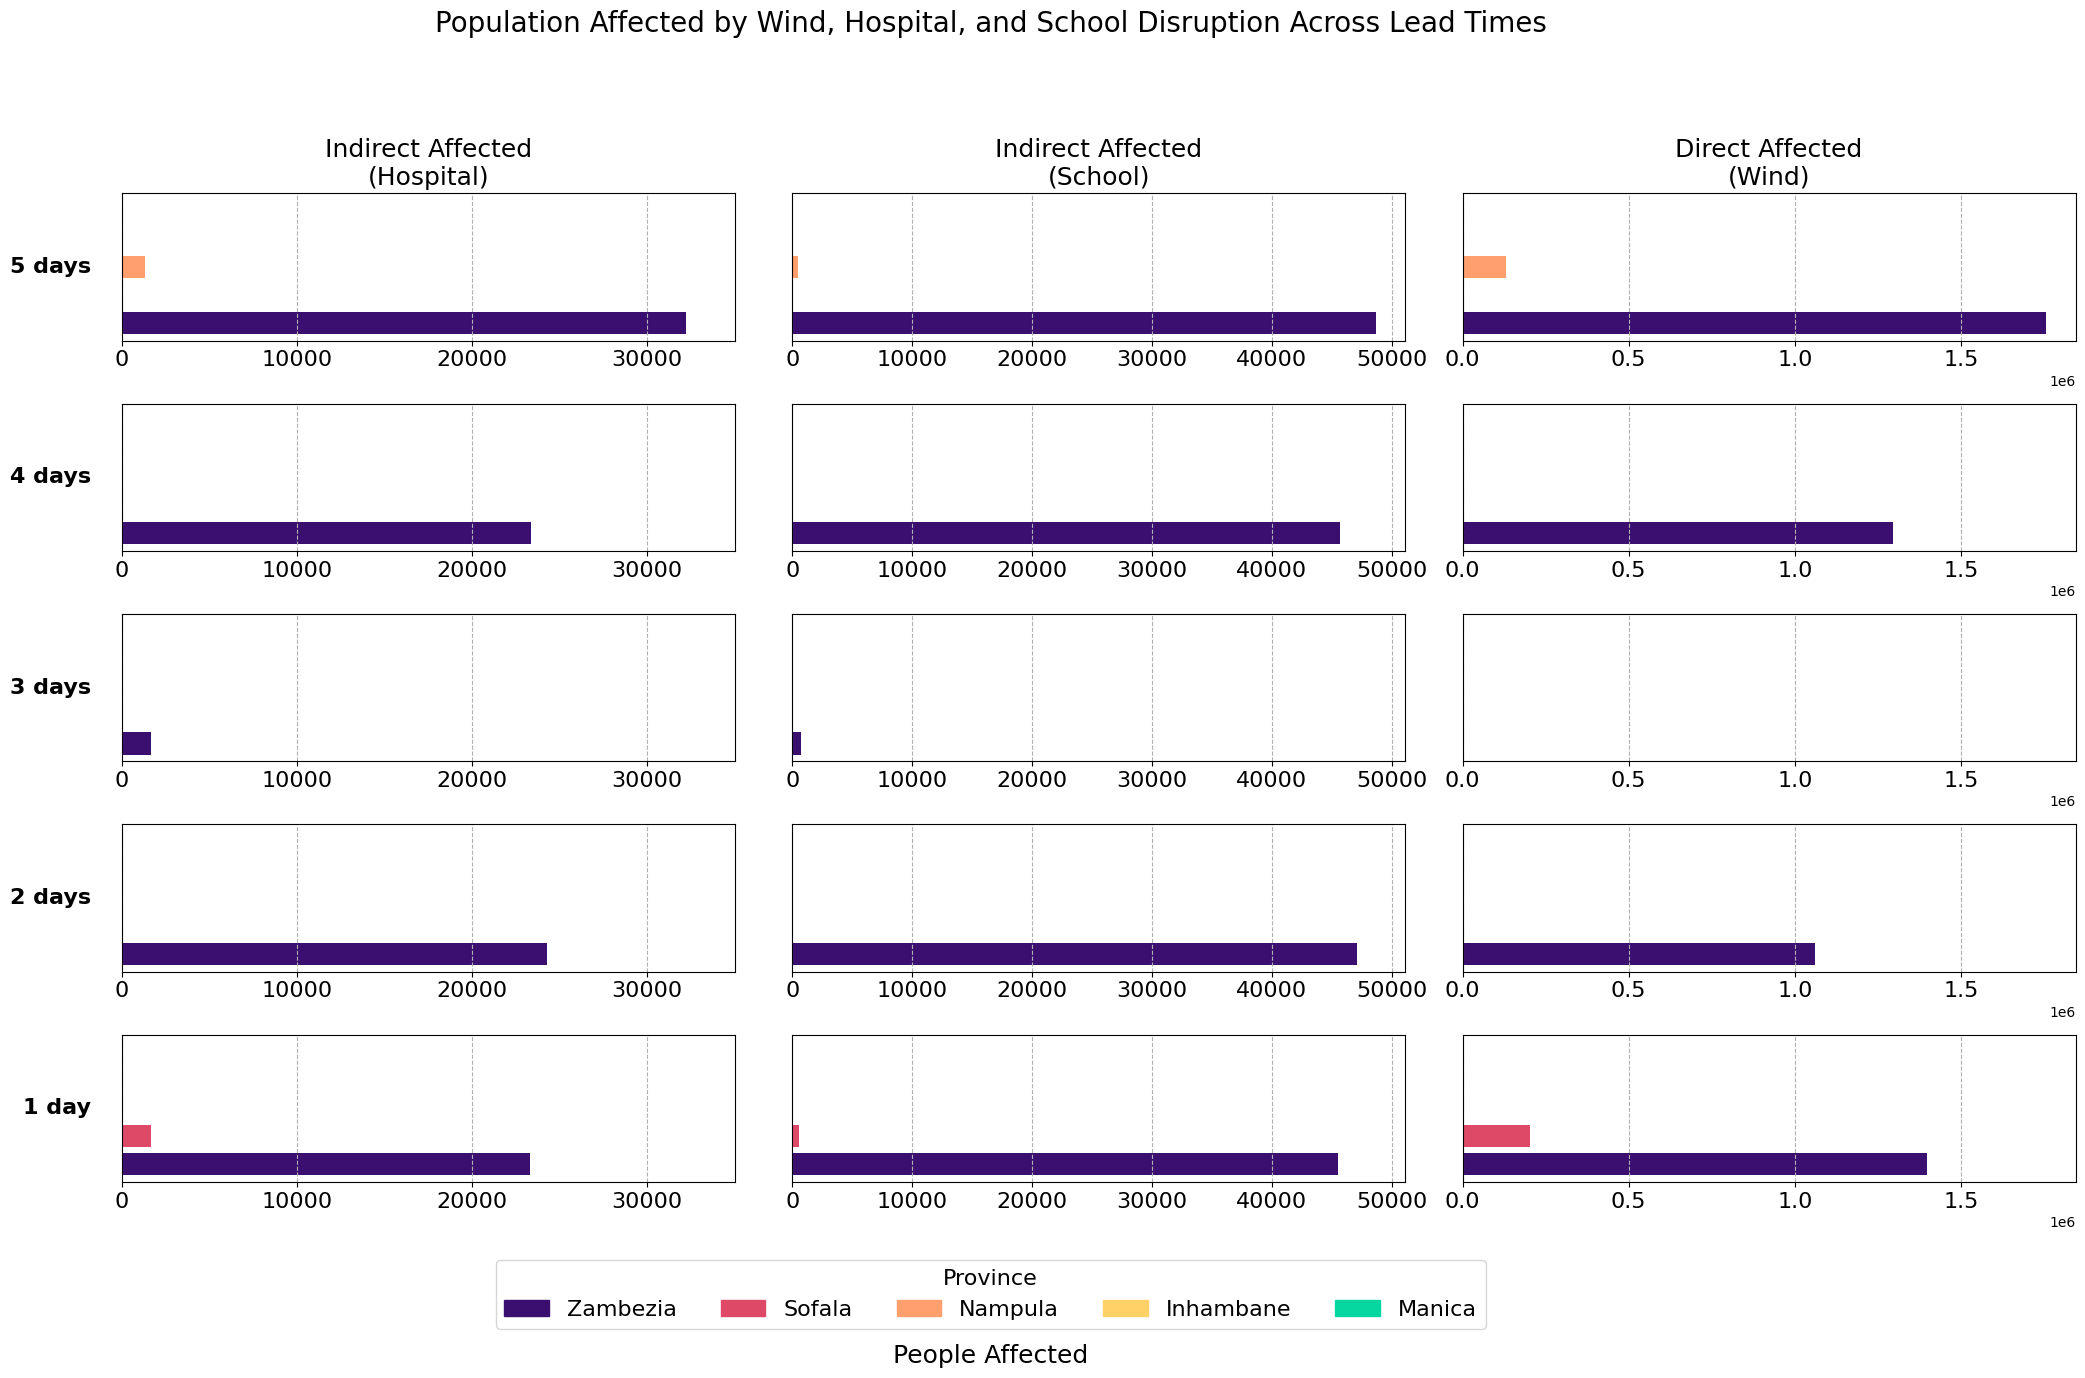

In [239]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch

# Define your lead times
lead_times = ['5 days','4 days', '3 days', '2 days', '1 day']

# Full list of provinces to plot
provinces = ['Zambezia', 'Sofala', 'Nampula', 'Inhambane', 'Manica']

# Define consistent colors for each province
province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}

# Initialize dictionaries
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}

# Aggregate data by lead time and province
for lt in lead_times:
    # Hospital
    df_h2 = imph2_impp1[lt]
    h2_sums = df_h2.groupby('NAME_1')['pp_affected'].sum()
    leadtime_province_h2[lt] = h2_sums

    # School
    df_ed2 = ed2_impp1[lt]
    ed2_sums = df_ed2.groupby('NAME_1')['pp_affected'].sum()
    leadtime_province_ed2[lt] = ed2_sums

    # Wind
    df_p1 = impp1_disrupted[lt]
    p1_sums = df_p1.groupby('NAME_1')['people'].sum()
    leadtime_province_p1[lt] = p1_sums

# Convert to DataFrames
df_h2 = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2 = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1 = pd.DataFrame(leadtime_province_p1).T.fillna(0)

# Ensure all expected provinces are included (even if 0s)
for df in [df_h2, df_ed2, df_p1]:
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    df = df[provinces]  # Reorder columns to match

# Plotting
fig, axes = plt.subplots(nrows=len(lead_times), ncols=3, figsize=(22, 14), sharey=True)

for i, lt in enumerate(lead_times):  # Top-down
    direct_vals = df_h2.loc[lt]
    school_vals = df_ed2.loc[lt]
    wind_vals = df_p1.loc[lt]

    # Hospital disruption (left)
    ax_hosp = axes[i, 0]
    for prov in provinces:
        ax_hosp.barh(prov, direct_vals[prov], color=province_colors[prov])
    ax_hosp.set_xlim(0, 35000)
    ax_hosp.set_xticks([0, 10000, 20000, 30000])
    ax_hosp.tick_params(axis='x', labelsize=16)
    ax_hosp.set_yticks([])
    ax_hosp.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_hosp.set_title("Indirect Affected\n(Hospital)", fontsize=18)
    ax_hosp.text(-0.05, 0.5, lt, transform=ax_hosp.transAxes,
                 fontsize=16, va='center', ha='right', fontweight='bold')

    # School disruption (middle)
    ax_school = axes[i, 1]
    for prov in provinces:
        ax_school.barh(prov, school_vals[prov], color=province_colors[prov])
    ax_school.set_xlim(0, df_ed2.values.max() * 1.05)
    ax_school.tick_params(axis='x', labelsize=16)
    ax_school.set_yticks([])
    ax_school.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_school.set_title("Indirect Affected\n(School)", fontsize=18)

    # Wind impact (right)
    ax_wind = axes[i, 2]
    for prov in provinces:
        ax_wind.barh(prov, wind_vals[prov], color=province_colors[prov])
    ax_wind.set_xlim(0, df_p1.values.max() * 1.05)
    ax_wind.set_xticks([0, 5e5, 1e6, 1.5e6])
    ax_wind.tick_params(axis='x', labelsize=16)
    ax_wind.set_yticks([])
    ax_wind.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_wind.set_title("Direct Affected\n(Wind)", fontsize=18)

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=16, fontsize=16, bbox_to_anchor=(0.5, 0.03))

# Labels and title
fig.supxlabel("People Affected", fontsize=18)
fig.suptitle("Population Affected by Wind, Hospital, and School Disruption Across Lead Times", fontsize=20)

plt.tight_layout(rect=[0.05, 0.07, 1, 0.93])
plt.show()

In [ ]:
###Combined with all infrastructure 

/scratch/tmp.33912107.gespejo/ipykernel_184098/2536089164.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.05, 0.07, 1, 0.93])


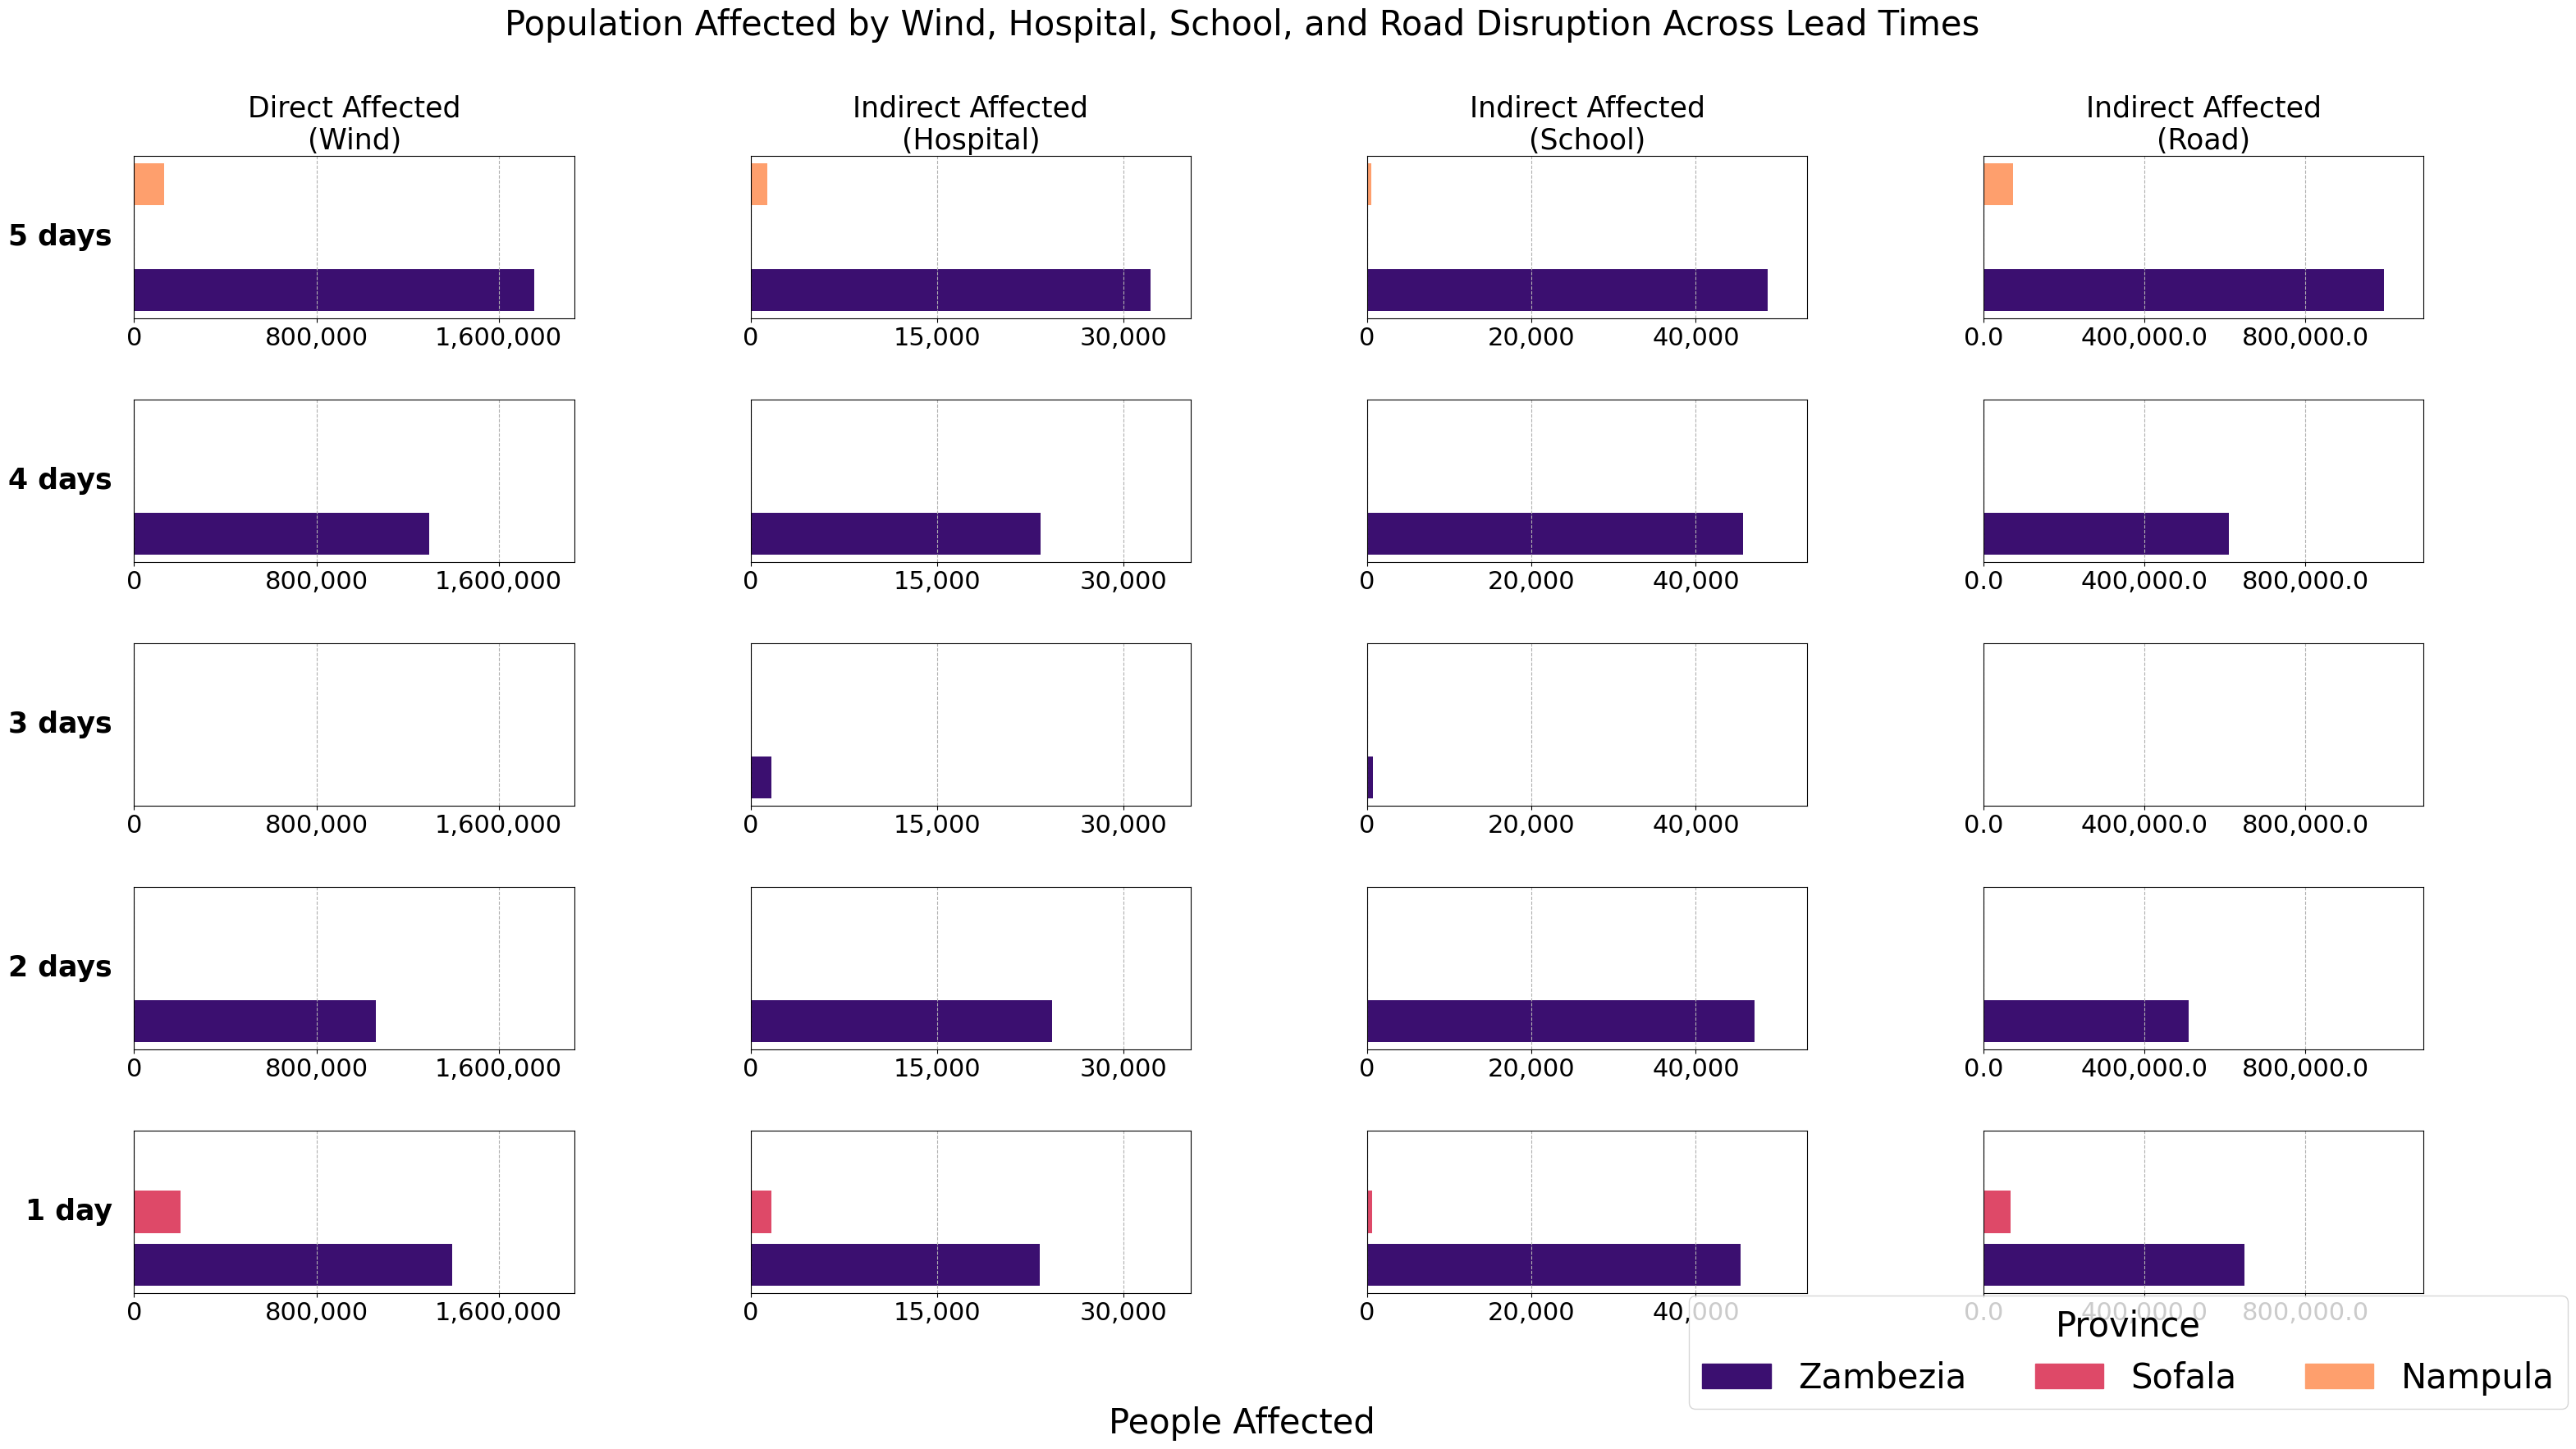

In [240]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2 = imph2_impp1[lt]
    leadtime_province_h2[lt] = df_h2.groupby('NAME_1')['pp_affected'].sum()

    df_ed2 = ed2_impp1[lt]
    leadtime_province_ed2[lt] = df_ed2.groupby('NAME_1')['pp_affected'].sum()

    df_p1 = impp1_disrupted[lt]
    leadtime_province_p1[lt] = df_p1.groupby('NAME_1')['people'].sum()

    df_rd2 = rd2_disrupted_impp1[lt]
    leadtime_province_rd2[lt] = df_rd2.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing provinces with 0
def complete_dataframe(d):
    df = pd.DataFrame(d).T
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    return df[provinces].fillna(0)

df_h2 = complete_dataframe(leadtime_province_h2)
df_ed2 = complete_dataframe(leadtime_province_ed2)
df_p1 = complete_dataframe(leadtime_province_p1)
df_rd2 = complete_dataframe(leadtime_province_rd2)

# Create figure and GridSpec
fig = plt.figure(figsize=(36, 18))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)

for i, lt in enumerate(lead_times):
    wind_vals = df_p1.loc[lt]
    hosp_vals = df_h2.loc[lt]
    school_vals = df_ed2.loc[lt]
    road_vals = df_rd2.loc[lt]

    for j, (vals, title, df_max, formatter) in enumerate([
        (wind_vals, "Direct Affected\n(Wind)", df_p1, StrMethodFormatter("{x:,.0f}")),
        (hosp_vals, "Indirect Affected\n(Hospital)", df_h2, StrMethodFormatter("{x:,.0f}")),
        (school_vals, "Indirect Affected\n(School)", df_ed2, StrMethodFormatter("{x:,.0f}")),
        (road_vals, "Indirect Affected\n(Road)", df_rd2, StrMethodFormatter("{x:,.1f}"))
    ]):
        ax = fig.add_subplot(gs[i, j])
        for prov in provinces:
            ax.barh(prov, vals.get(prov, 0), color=province_colors[prov])
        ax.set_xlim(0, df_max.values.max() * 1.1)
        ax.xaxis.set_major_formatter(formatter)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=22)
        ax.xaxis.get_offset_text().set_fontsize(22)
        ax.set_yticks([])
        ax.grid(axis='x', linestyle='--', alpha=1)
        if i == 0:
            ax.set_title(title, fontsize=25)
        if j == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=30, fontsize=30, bbox_to_anchor=(0.8, 0.02))

# Labels
fig.supxlabel("People Affected", fontsize=30)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=30)

plt.tight_layout(rect=[0.05, 0.07, 1, 0.93])
plt.show()

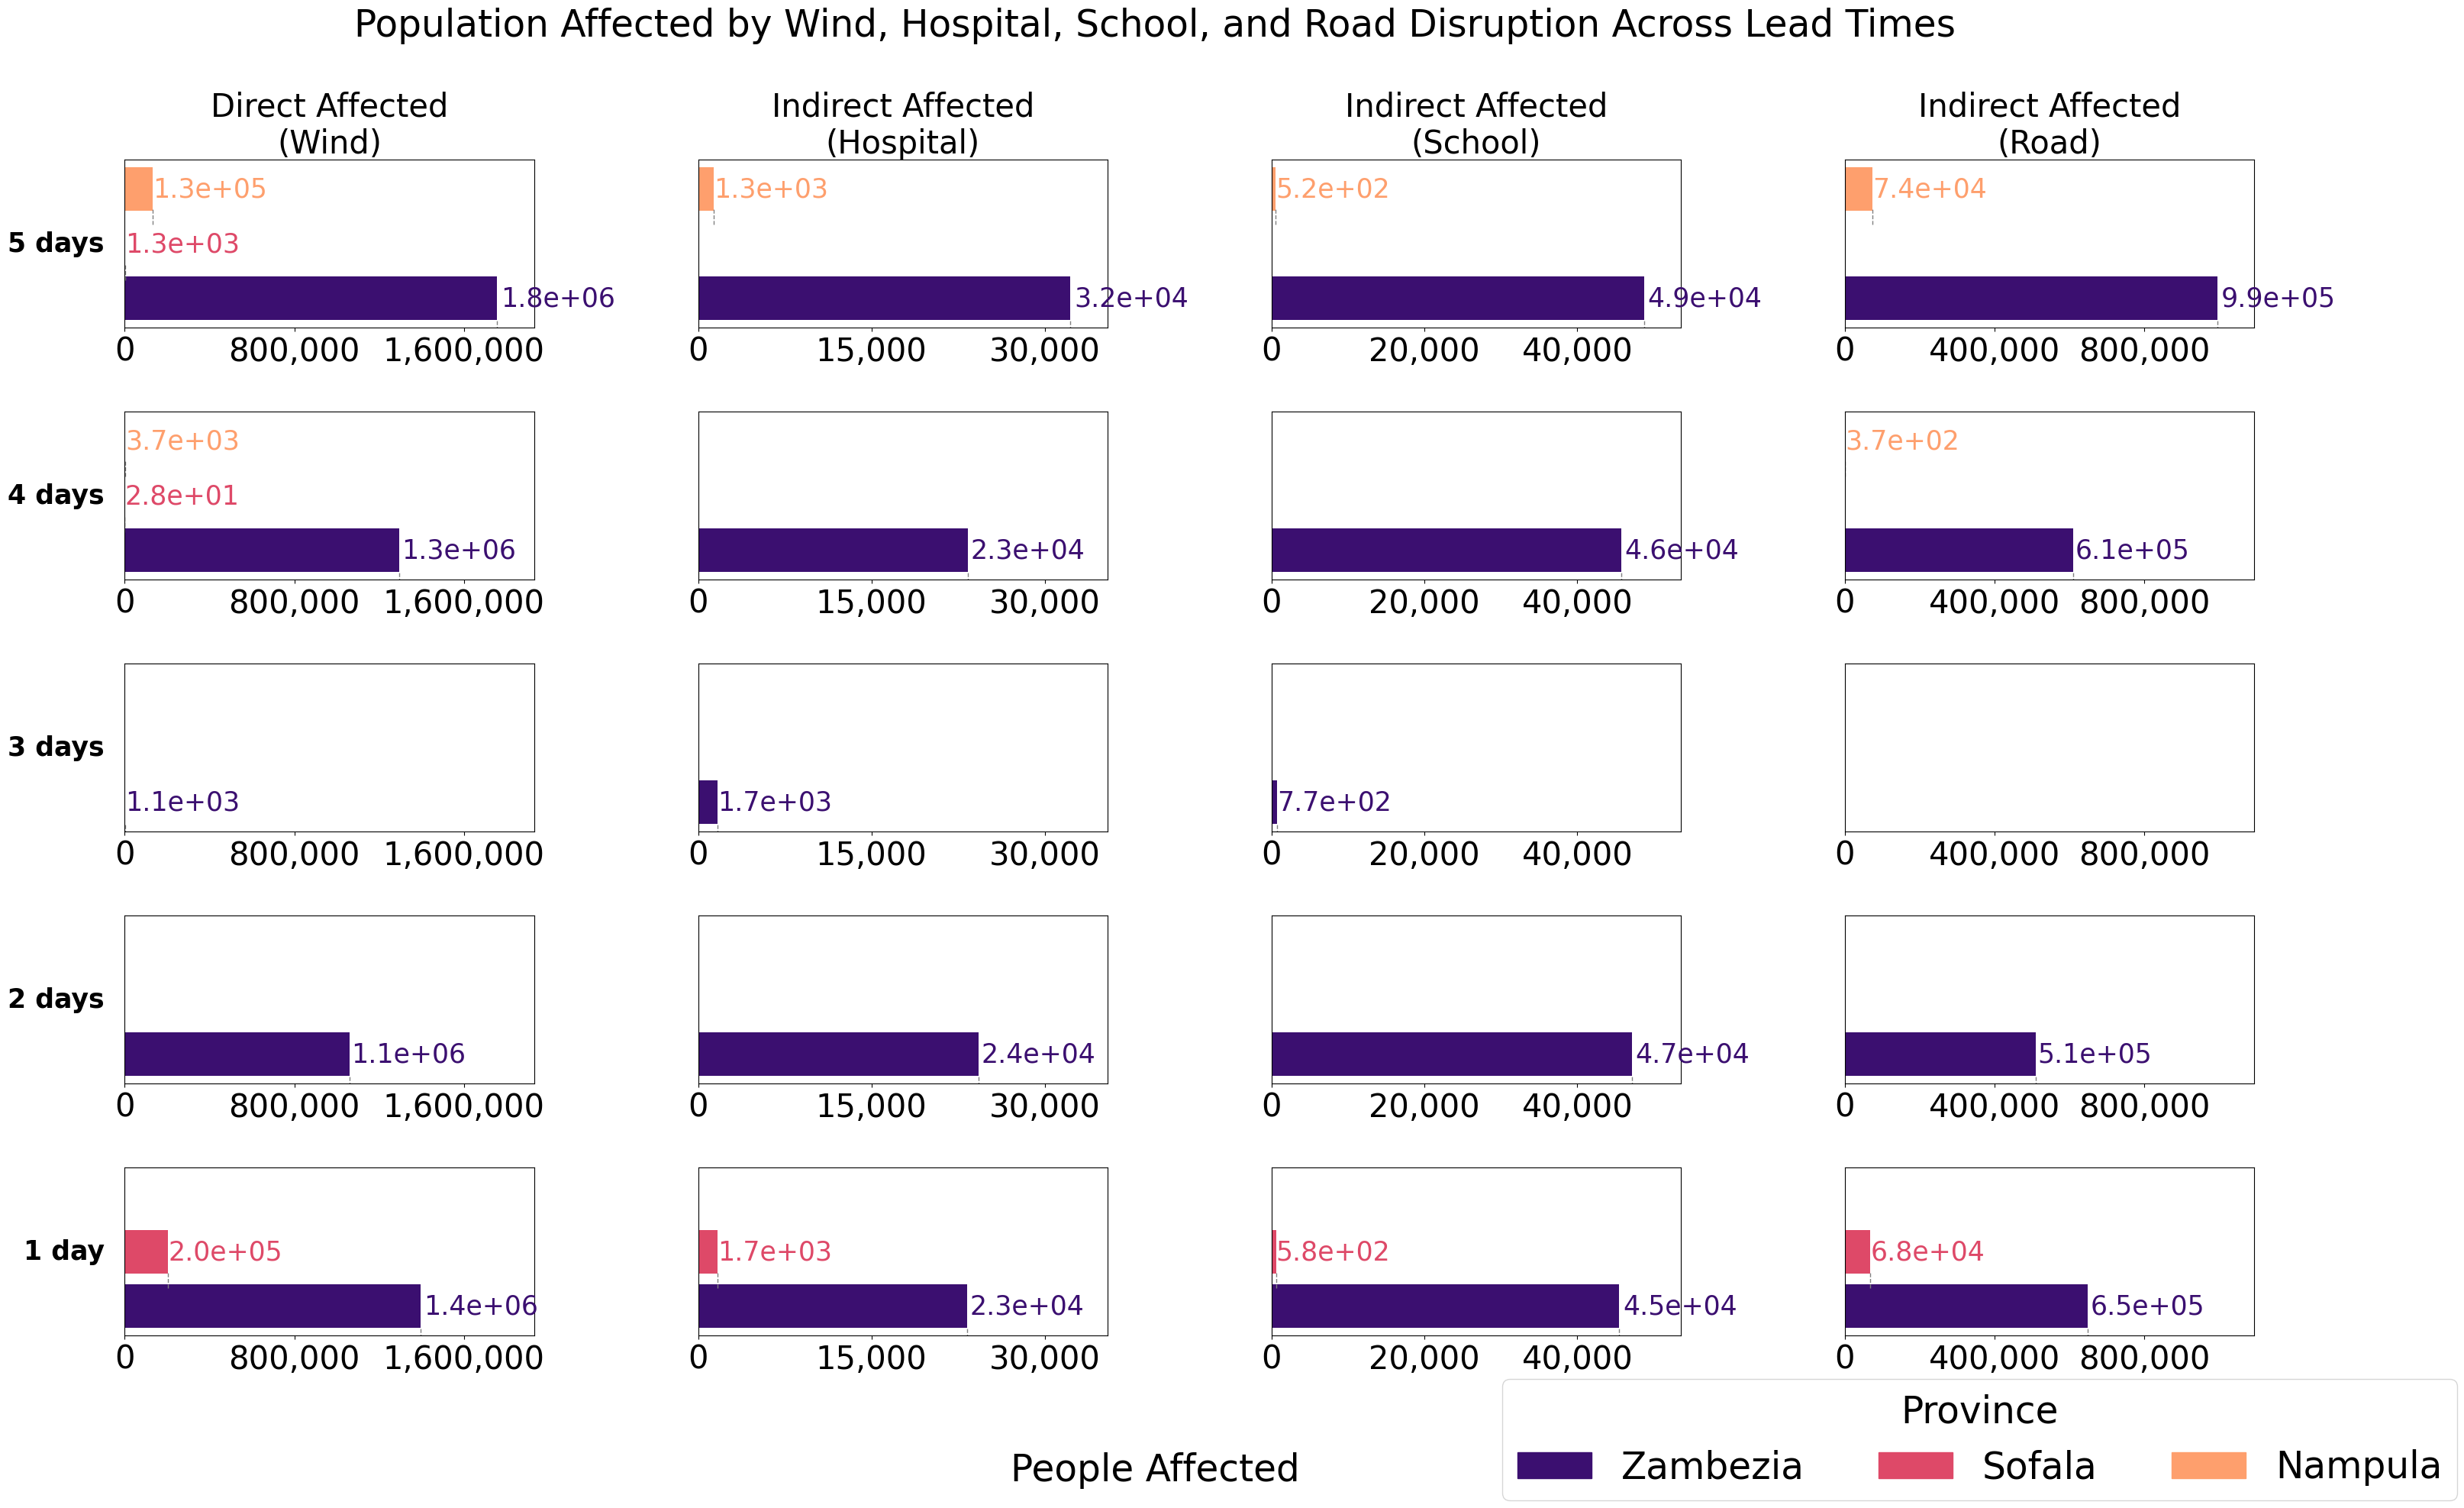

In [60]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate and reindex to ensure consistency
for lt in lead_times:
    leadtime_province_h2[lt] = (
        imph2_impp1[lt].groupby('NAME_1')['pp_affected'].sum().reindex(provinces, fill_value=0)
    )
    leadtime_province_ed2[lt] = (
        ed2_impp1[lt].groupby('NAME_1')['pp_affected'].sum().reindex(provinces, fill_value=0)
    )
    leadtime_province_p1[lt] = (
        impp1_disrupted[lt].groupby('NAME_1')['people'].sum().reindex(provinces, fill_value=0)
    )
    leadtime_province_rd2[lt] = (
        rd2_disrupted_impp1[lt].groupby('NAME_1')['pp_affected'].sum().reindex(provinces, fill_value=0)
    )

# Convert to DataFrames
df_h2 = pd.DataFrame(leadtime_province_h2).T[provinces]
df_ed2 = pd.DataFrame(leadtime_province_ed2).T[provinces]
df_p1 = pd.DataFrame(leadtime_province_p1).T[provinces]
df_rd2 = pd.DataFrame(leadtime_province_rd2).T[provinces]

# Create figure and GridSpec
fig = plt.figure(figsize=(36, 20))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)
axes = np.empty((len(lead_times), 4), dtype=object)

# Helper: vertical line and label
def draw_bar_end_line(ax, value, y, color):
    if value > 0:
        ax.axvline(x=value, ymin=(y - 0.15)/len(provinces), ymax=(y + 0.15)/len(provinces),
                   color='gray', linestyle='--', linewidth=1)
        ax.text(value * 1.01, y, f"{value:.1e}", fontsize=25, va='center', ha='left', color=color)

# Plotting
for i, lt in enumerate(lead_times):
    row_vals = [
        (df_p1.loc[lt], "Direct Affected\n(Wind)", df_p1.values.max()),
        (df_h2.loc[lt], "Indirect Affected\n(Hospital)", df_h2.values.max()),
        (df_ed2.loc[lt], "Indirect Affected\n(School)", df_ed2.values.max()),
        (df_rd2.loc[lt], "Indirect Affected\n(Road)", df_rd2.values.max())
    ]

    for col, (vals, title, maxval) in enumerate(row_vals):
        ax = fig.add_subplot(gs[i, col])
        for j, prov in enumerate(provinces):
            val = vals.get(prov, 0)
            ax.barh(j, val, color=province_colors[prov])
            draw_bar_end_line(ax, val, j, province_colors[prov])

        ax.set_xlim(0, maxval * 1.1 if maxval > 0 else 1)
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=30)
        ax.set_yticks([])
        ax.grid(False)
        if i == 0:
            ax.set_title(title, fontsize=30)
        if col == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')
        axes[i, col] = ax

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=35, fontsize=35, bbox_to_anchor=(0.8, -0.01))

# Labels and Title
fig.supxlabel("People Affected", fontsize=35)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=35)

# Save and show
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_people_FREDDY.png", dpi=300, bbox_inches='tight')
plt.show()

In [242]:
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'imph2_impp1.pkl', 'wb') as file:
    pickle.dump(imph2_impp1, file)
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'ed2_impp1.pkl', 'wb') as file:
    pickle.dump(ed2_impp1, file)
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'impp1_disrupted.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted, file)
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'rd2_disrupted_impp1.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1, file)

In [121]:
## then we will calculate it when we use categorization 1 cat 

In [122]:
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/imph1_cat.pkl', 'rb') as file:
    imph1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/ed1_cat.pkl', 'rb') as file:
    ed1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/impp1_cat.pkl', 'rb') as file:
    impp1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/rd1_51ens_cat.pkl', 'rb') as file:
    rd1_51ens_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/exp_dict_cat.pkl', 'rb') as file:
    exp_dict_cat = pickle.load(file)

In [123]:
### 
def calculate_direct_and_indirect_impacts(
    imph2, imps2, impp1, rd2_51ens,
    exp_rd2_gdf, gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
):
    # 1. Disrupted hospitals
    disrupted_hospitals = get_disrupted_exposures_and_ensemble(imph2, threshold=0.20, min_members=5, mode="above")
    disrupted_hospitals_copy = disrupted_hospitals.copy()
    
    # 2. Disrupted schools
    disrupted_schools = get_disrupted_exposures_and_ensemble(imps2, threshold=0.20, min_members=5, mode="above")
    disrupted_schools_copy = disrupted_schools.copy()
    
    # 3. Disrupted infrastructure (e.g. wind): add population + region
    impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")
    impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf, gadm_MOZ_gdf)
    impp1_disrupted_copy = impp1_disrupted.copy()
    
    # 4. Disrupted roads
    rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_rd2_gdf)
    mimpact_cols_scale(rd2_mimpact, 500.0)
    rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")
    rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
    rd2_disrupted_copy = rd2_disrupted.copy()
    
    # 5. Indirect impacts
    imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)
    ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)
    rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)
    rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)
    
    return imph2_impp1, ed2_impp1, impp1_disrupted_copy, rd2_disrupted_impp1

In [124]:
imph1_impp1_cat, ed1_impp1_cat, impp1_disrupted_copy_cat, rd1_disrupted_impp1_cat = calculate_direct_and_indirect_impacts(
    imph1_cat, ed1_cat, impp1, rd1_51ens_cat,
    exp_dict_cat['exp_rd1_MOZ'].gdf, gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
)

/scratch/tmp.33912107.gespejo/ipykernel_184098/2390560494.py:28: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gadm_MOZ_gdf.geometry.centroid


 222412 unmatched points in impp1_MOZ_FREDDY_20230306120000 — assigning nearest NAME_1 using KDTree...
 178720 unmatched points in impp1_MOZ_FREDDY_20230307120000 — assigning nearest NAME_1 using KDTree...
 58099 unmatched points in impp1_MOZ_FREDDY_20230308120000 — assigning nearest NAME_1 using KDTree...
 56150 unmatched points in impp1_MOZ_FREDDY_20230309120000 — assigning nearest NAME_1 using KDTree...
 57574 unmatched points in impp1_MOZ_FREDDY_20230310120000 — assigning nearest NAME_1 using KDTree...
 10333 unmatched points in impp1_MOZ_FREDDY_20230311120000 — assigning nearest NAME_1 using KDTree...

🔍 Starting nearest population match for 6 lead times...

➡️  Processing: imph1_MOZ_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230306120000

➡️  Processing: imph1_MOZ_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_FREDDY_20230307120000

➡️  Proces

In [126]:
imph1_impp1_cat_dict_rename = {
    'imph1_MOZ_FREDDY_20230306120000': '5 days',
    'imph1_MOZ_FREDDY_20230307120000': '4 days',
    'imph1_MOZ_FREDDY_20230308120000': '3 days',
    'imph1_MOZ_FREDDY_20230309120000': '2 days',
    'imph1_MOZ_FREDDY_20230310120000': '1 day',
    'imph1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
imph1_impp1_cat = {imph1_impp1_cat_dict_rename.get(k, k): v for k, v in imph1_impp1_cat.items() if k in imph1_impp1_cat_dict_rename}

In [127]:
ed1_impp1_cat_dict_rename = {
    'ed1_MOZ_FREDDY_20230306120000': '5 days',
    'ed1_MOZ_FREDDY_20230307120000': '4 days',
    'ed1_MOZ_FREDDY_20230308120000': '3 days',
    'ed1_MOZ_FREDDY_20230309120000': '2 days',
    'ed1_MOZ_FREDDY_20230310120000': '1 day',
    'ed1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
ed1_impp1_cat = {ed1_impp1_cat_dict_rename.get(k, k): v for k, v in ed1_impp1_cat.items() if k in ed1_impp1_cat_dict_rename}

In [128]:
impp1_cat_dict_rename = {
    'impp1_MOZ_FREDDY_20230306120000': '5 days',
    'impp1_MOZ_FREDDY_20230307120000': '4 days',
    'impp1_MOZ_FREDDY_20230308120000': '3 days',
    'impp1_MOZ_FREDDY_20230309120000': '2 days',
    'impp1_MOZ_FREDDY_20230310120000': '1 day',
    'impp1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
impp1_disrupted_copy_cat = {impp1_cat_dict_rename.get(k, k): v for k, v in impp1_disrupted_copy_cat.items() if k in impp1_cat_dict_rename}

In [129]:
rd1_impp1_cat_dict_rename = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}
# Rename keys using rename_dict
rd1_disrupted_impp1_cat = {rd1_impp1_cat_dict_rename.get(k, k): v for k, v in rd1_disrupted_impp1_cat.items() if k in rd1_impp1_cat_dict_rename}

In [130]:
### Results with categories calculated for the impacts 

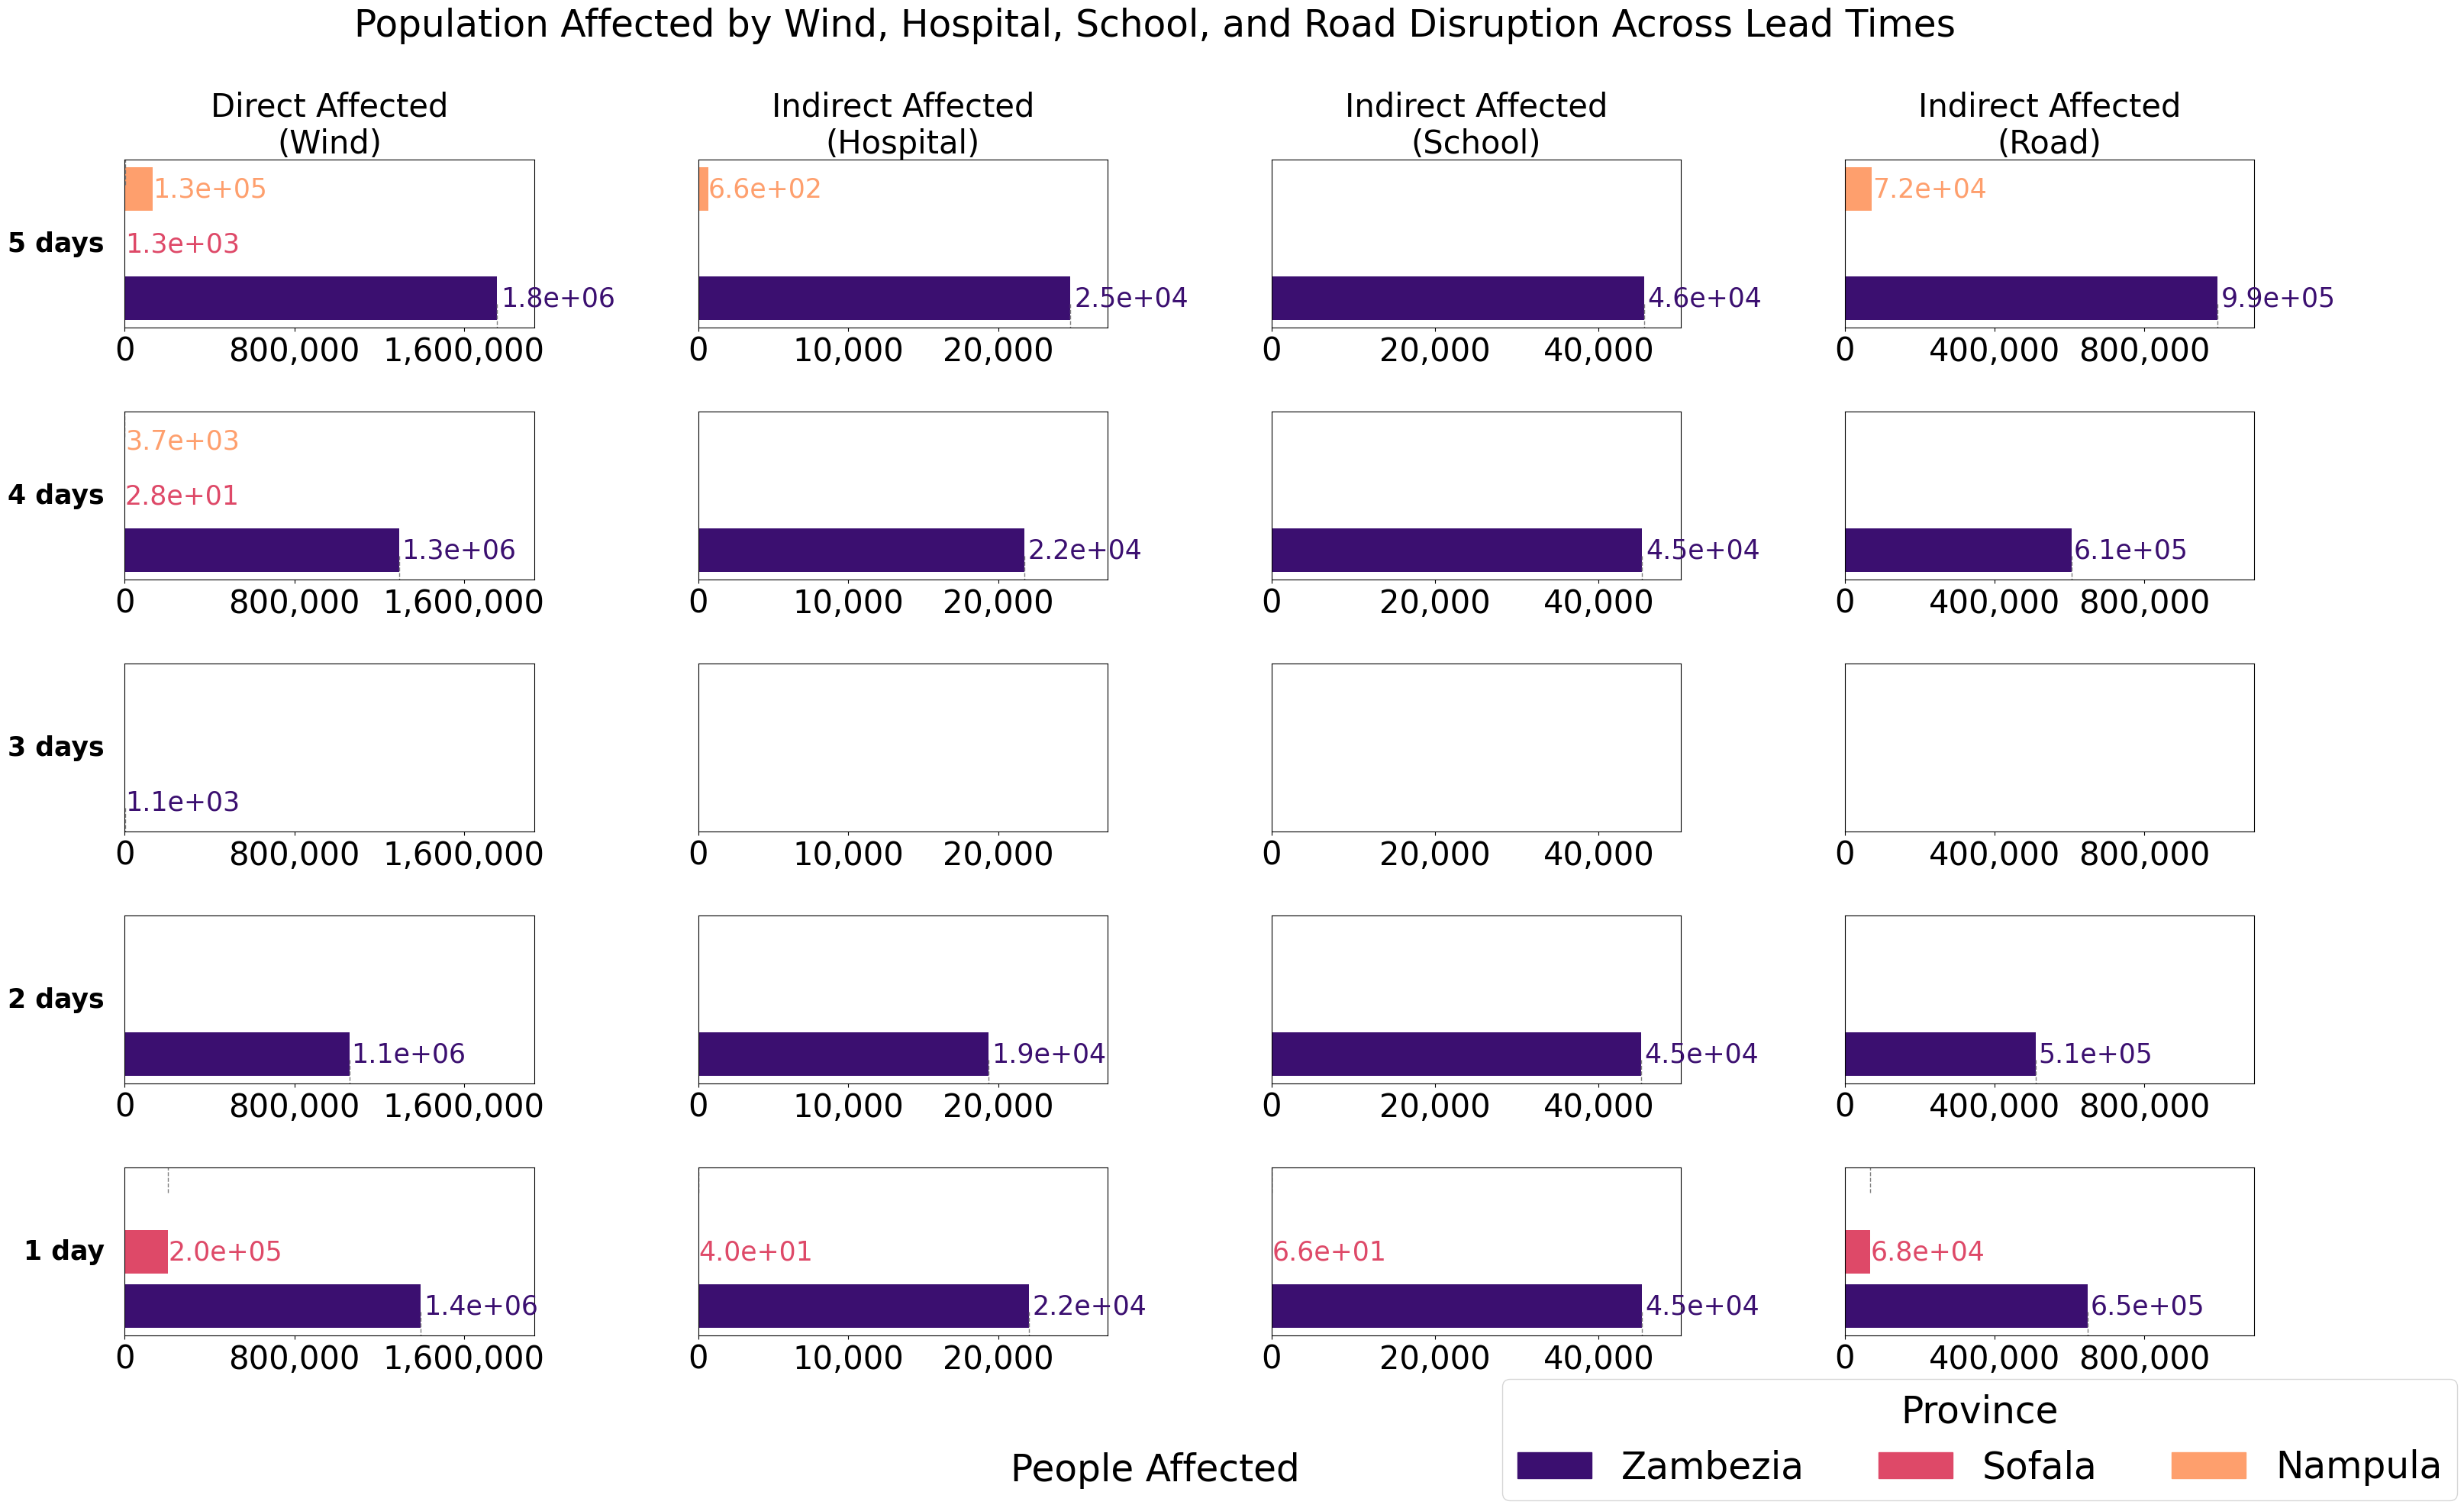

In [131]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']
province_colors = {
    'Zambezia': '#3b0f70',
    'Sofala':   '#de4968',
    'Nampula':  '#fe9f6d'
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h1_cat = {}
leadtime_province_ed1_cat = {}
leadtime_province_p1_cat = {}
leadtime_province_rd1_cat = {}

# Aggregate safely per lead time and province
for lt in lead_times:
    # Wind (direct)
    if lt in impp1_disrupted_copy_cat:
        df_p1_cat = impp1_disrupted_copy_cat[lt]
        leadtime_province_p1_cat[lt] = df_p1_cat.groupby('NAME_1')['people'].sum()
    else:
        leadtime_province_p1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # Hospital
    if lt in imph1_impp1_cat:
        df_h1_cat = imph1_impp1_cat[lt]
        leadtime_province_h1_cat[lt] = df_h1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_h1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # School
    if lt in ed1_impp1_cat:
        df_ed1_cat = ed1_impp1_cat[lt]
        leadtime_province_ed1_cat[lt] = df_ed1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_ed1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # Road
    if lt in rd1_disrupted_impp1_cat:
        df_rd1_cat = rd1_disrupted_impp1_cat[lt]
        leadtime_province_rd1_cat[lt] = df_rd1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_rd1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

# Convert to DataFrames and fill missing entries
df_h1_cat = pd.DataFrame(leadtime_province_h1_cat).T.fillna(0)
df_ed1_cat = pd.DataFrame(leadtime_province_ed1_cat).T.fillna(0)
df_p1_cat = pd.DataFrame(leadtime_province_p1_cat).T.fillna(0)
df_rd1_cat = pd.DataFrame(leadtime_province_rd1_cat).T.fillna(0)

# Create figure and GridSpec
fig = plt.figure(figsize=(36, 20))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)
axes = np.empty((len(lead_times), 4), dtype=object)

# Draw helper
def draw_bar_end_line(ax, value, y, color):
    ax.axvline(x=value, ymin=y-0.15, ymax=y+0.15, color='gray', linestyle='--', linewidth=1)
    ax.text(value * 1.01, y, f"{value:.1e}", fontsize=25, va='center', ha='left', color=color)

for i, lt in enumerate(lead_times):
    wind_vals = df_p1_cat.loc[lt]
    hosp_vals = df_h1_cat.loc[lt]
    school_vals = df_ed1_cat.loc[lt]
    road_vals = df_rd1_cat.loc[lt]

    for col, (vals, title, maxval) in enumerate([
        (wind_vals,   "Direct Affected\n(Wind)",    df_p1_cat.values.max()),
        (hosp_vals,   "Indirect Affected\n(Hospital)", df_h1_cat.values.max()),
        (school_vals, "Indirect Affected\n(School)",   df_ed1_cat.values.max()),
        (road_vals,   "Indirect Affected\n(Road)",     df_rd1_cat.values.max())
    ]):
        ax = fig.add_subplot(gs[i, col])
        for j, prov in enumerate(provinces):
            val = vals.get(prov, 0)
            ax.barh(j, val, color=province_colors[prov])
            if val > 0:
                draw_bar_end_line(ax, val, j, province_colors[prov])

        ax.set_xlim(0, maxval * 1.1 if maxval > 0 else 1)
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=30)
        ax.set_yticks([])
        ax.grid(False)
        if i == 0:
            ax.set_title(title, fontsize=30)
        if col == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')
        axes[i, col] = ax

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=35, fontsize=35, bbox_to_anchor=(0.8, -0.01))

# Axis and title
fig.supxlabel("People Affected", fontsize=35)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=35)

fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_people_FREDDY_cat", dpi=800, bbox_inches='tight')
plt.show()